In [1]:
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from boruta import BorutaPy
from sklearn.svm import SVR
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
df = pd.read_csv('NASA_2020_2023.csv')
df

,YEAR,MO,DY,HR,ALLSKY_SFC_SW_DWN,T2M,RH2M,PS,WS10M,WD10M
0,2020,1,1,0,0.0,9.67,85.81,98.54,4.30,9.74
1,2020,1,1,1,0.0,9.45,88.69,98.51,4.31,11.09
2,2020,1,1,2,0.0,9.24,91.75,98.47,4.34,10.89
3,2020,1,1,3,0.0,9.02,94.75,98.43,4.36,9.28
4,2020,1,1,4,0.0,9.03,95.94,98.42,4.27,8.74
...,...,...,...,...,...,...,...,...,...,...
35083,2024,1,1,19,0.0,14.56,75.81,98.59,4.58,332.61
35084,2024,1,1,20,0.0,14.26,79.94,98.62,4.65,335.93
35085,2024,1,1,21,0.0,14.50,80.25,98.64,4.62,342.36
35086,2024,1,1,22,0.0,14.24,81.56,98.64,4.61,348.96


In [3]:
df['All Sky Surface Shortwave Downward Irradiance'] = df['ALLSKY_SFC_SW_DWN']
df['Temperature at 2 Meters'] = df['T2M']
df['Relative Humidity at 2 Meters'] = df['RH2M']
df['Surface Pressure'] = df['PS']
df['Wind Speed at 10 Meters'] = df['WS10M']
df['Wind Direction at 10 Meters'] = df['WD10M']

df = df.drop(columns=['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PS', 'WS10M', 'WD10M'])
df

,YEAR,MO,DY,HR,All Sky Surface Shortwave Downward Irradiance,Temperature at 2 Meters,Relative Humidity at 2 Meters,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 10 Meters
0,2020,1,1,0,0.0,9.67,85.81,98.54,4.30,9.74
1,2020,1,1,1,0.0,9.45,88.69,98.51,4.31,11.09
2,2020,1,1,2,0.0,9.24,91.75,98.47,4.34,10.89
3,2020,1,1,3,0.0,9.02,94.75,98.43,4.36,9.28
4,2020,1,1,4,0.0,9.03,95.94,98.42,4.27,8.74
...,...,...,...,...,...,...,...,...,...,...
35083,2024,1,1,19,0.0,14.56,75.81,98.59,4.58,332.61
35084,2024,1,1,20,0.0,14.26,79.94,98.62,4.65,335.93
35085,2024,1,1,21,0.0,14.50,80.25,98.64,4.62,342.36
35086,2024,1,1,22,0.0,14.24,81.56,98.64,4.61,348.96


### Anova Feature Selection

Selected feature names: ['Temperature at 2 Meters', 'Relative Humidity at 2 Meters', 'Wind Speed at 10 Meters', 'Surface Pressure', 'DY', 'YEAR', 'Wind Direction at 10 Meters', 'MO', 'HR']
the number of features:  9
Seelcted Features Scores:  [('Temperature at 2 Meters', 1.8762645022121924), ('Relative Humidity at 2 Meters', 1.8219887301002926), ('Wind Speed at 10 Meters', 1.680270295038168), ('Surface Pressure', 1.0920854692274227), ('DY', 1.001190920143413), ('YEAR', 0.9893652939511235), ('Wind Direction at 10 Meters', 0.9886830394805155), ('MO', 0.8377903654783622), ('HR', 0.16756454353600841)]


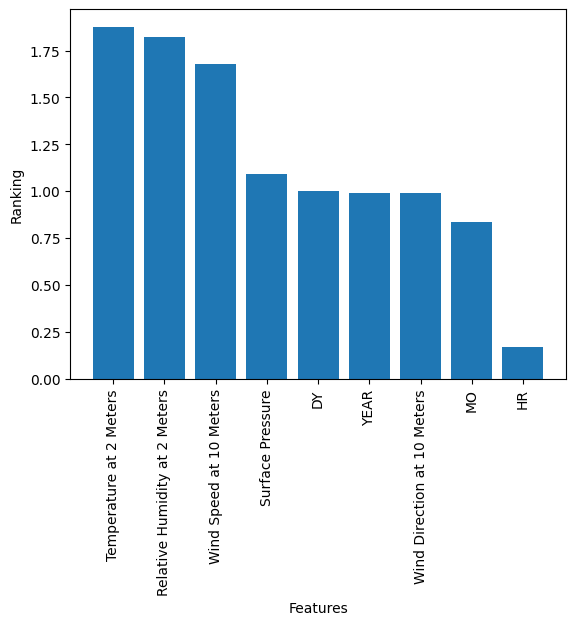

In [4]:
X = df.drop(columns=['All Sky Surface Shortwave Downward Irradiance'])
y = df['All Sky Surface Shortwave Downward Irradiance']

selector = SelectKBest(f_classif, k=9)  # Select top 9 features
X_new = selector.fit_transform(X, y)
scores = selector.scores_
selected_feature_indices = selector.get_support(indices=True)
selected_features_with_scores = [(X.columns[i], scores[i]) for i in selected_feature_indices]
selected_features_with_scores.sort(key=lambda x: x[1], reverse=True)
sorted_selected_feature_names = [feature[0] for feature in selected_features_with_scores]
#selected_feature_names = X.columns[selected_feature_indices]
print("Selected feature names:", sorted_selected_feature_names)
print("the number of features: ", len(sorted_selected_feature_names))
print("Seelcted Features Scores: ", selected_features_with_scores)

#print = pd.DataFrame(selected_features_with_scores)
#print.to_csv('Anova.csv')

plt.bar([feature[0] for feature in selected_features_with_scores], [feature[1] for feature in selected_features_with_scores])
plt.xticks(rotation=90)
plt.xlabel('Features')
plt.ylabel('Ranking')
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Boruta Feature Selection

Boruta Ranking:  [2 1 1 1 1 1 1 1 1]
No. of significant features:  8


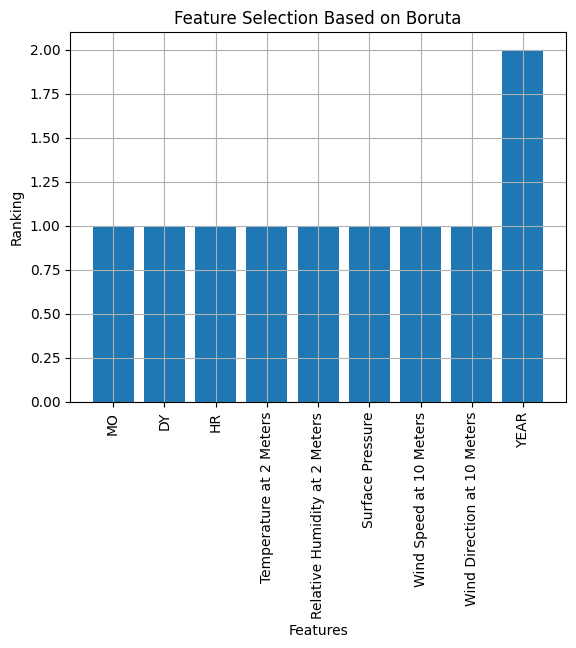

In [21]:
model = RandomForestRegressor()
boruta_selector = BorutaPy(model, n_estimators='auto', verbose=0, random_state=1, max_iter=100)
boruta_selector.fit(X.values, y.values)
print("Boruta Ranking: ", boruta_selector.ranking_)
print("No. of significant features: ", boruta_selector.n_features_)
selected_rf_features = pd.DataFrame({
    'Feature': list(X.columns),
    'Ranking': boruta_selector.ranking_
}).sort_values(by='Ranking')
# Selecting the columns with ranking 1
new_columns = selected_rf_features[selected_rf_features["Ranking"] == 1]['Feature']
X_new = X[new_columns]

selected_rf_features.to_csv('Boruta.csv')

plt.bar(selected_rf_features['Feature'], selected_rf_features['Ranking'])
plt.xticks(rotation=90)
plt.grid()
plt.title("Feature Selection Based on Boruta")
plt.xlabel("Features")
plt.ylabel("Ranking")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

In [5]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

mse = mean_squared_error(y_test, lr_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, lr_pred)
mae = mean_absolute_error(y_test, lr_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 46805.391564554
RMSE: 216.34553742694578
R2: 0.5862504181196881
MAE: 176.91869531890674


In [6]:
gb = GradientBoostingRegressor()
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

mse = mean_squared_error(y_test, gb_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, gb_pred)
mae = mean_absolute_error(y_test, gb_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 2353.6806091261237
RMSE: 48.514746305902946
R2: 0.9791939702809105
MAE: 30.52746083695231


In [8]:
dt = DecisionTreeRegressor()
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

mse = mean_squared_error(y_test, dt_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, dt_pred)
mae = mean_absolute_error(y_test, dt_pred)

with open('Solar_dt.pkl', 'wb') as file:
    pickle.dump(dt, file)


print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 2290.0203491664292
RMSE: 47.85415707299032
R2: 0.9797567132697046
MAE: 19.070147477913938


In [12]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

feat = [features[i] for i in indices]
dat = pd.DataFrame({
    'Feature': feat,
    'Importance': importances
})
dat.to_csv('Random_Forest.csv')

'''plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=90)
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()'''
rf_pred = rf.predict(X_test)

#with open('Solar_rf.pkl', 'wb') as file:
#    pickle.dump(rf, file)

mse = mean_squared_error(y_test, rf_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, rf_pred)
mae = mean_absolute_error(y_test, rf_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 1139.3026646775008
RMSE: 33.753557807696374
R2: 0.9899288097933054
MAE: 14.182243046451982


In [42]:
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.4, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(21052, 9) (8421, 9) (5615, 9)


In [44]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=2, monitor='val_loss')

X_train = np.expand_dims(X_train, axis=1)
X_test = np.expand_dims(X_test, axis=1)
#X_val = np.expand_dims(X_val, axis=1)
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation='linear'),
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

cnn_pred = model.predict(X_test)

mse = mean_squared_error(y_test, cnn_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, cnn_pred)
mae = mean_absolute_error(y_test, cnn_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/20
658/658 [==============================] - 4s 6ms/step - loss: 102006.8828 - val_loss: 91000.3594
Epoch 2/20
658/658 [==============================] - 3s 4ms/step - loss: 75609.7031 - val_loss: 68460.1953
Epoch 3/20
658/658 [==============================] - 3s 4ms/step - loss: 64430.7617 - val_loss: 63776.9844
Epoch 4/20
658/658 [==============================] - 3s 4ms/step - loss: 60604.5039 - val_loss: 60741.9414
Epoch 5/20
658/658 [==============================] - 3s 4ms/step - loss: 58499.9961 - val_loss: 57613.2500
Epoch 6/20
658/658 [==============================] - 3s 5ms/step - loss: 56723.0742 - val_loss: 56430.8477
Epoch 7/20
658/658 [==============================] - 3s 5ms/step - loss: 55374.9453 - val_loss: 55237.4453
Epoch 8/20
658/658 [==============================] - 3s 5ms/step - loss: 54363.2578 - val_loss: 53848.2656
Epoch 9/20
658/658 [==============================] - 3s 4ms/step - loss: 53421.0781 - val_loss: 53613.3086
Epoch 10/20
658/658 [======

In [45]:
model_lstm = tf.keras.models.Sequential([
    tf.keras.layers.LSTM(32, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_lstm.compile(optimizer='adam', loss='mse')

model_lstm.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model_lstm.predict(X_test)
y_pred = np.squeeze(y_pred)
lstm_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, lstm_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, lstm_pred)
mae = mean_absolute_error(y_test, lstm_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
658/658 [==============================] - 7s 9ms/step - loss: 109125.9844 - val_loss: 108180.0234
Epoch 2/1000
658/658 [==============================] - 6s 9ms/step - loss: 99218.8516 - val_loss: 95157.7422
Epoch 3/1000
658/658 [==============================] - 5s 8ms/step - loss: 83671.0703 - val_loss: 77857.1797
Epoch 4/1000
658/658 [==============================] - 6s 9ms/step - loss: 71081.5312 - val_loss: 69824.9219
Epoch 5/1000
658/658 [==============================] - 5s 7ms/step - loss: 65597.6797 - val_loss: 65247.4219
Epoch 6/1000
658/658 [==============================] - 5s 7ms/step - loss: 62412.3672 - val_loss: 62834.0547
Epoch 7/1000
658/658 [==============================] - 4s 7ms/step - loss: 60162.4258 - val_loss: 60111.3633
Epoch 8/1000
658/658 [==============================] - 4s 7ms/step - loss: 58550.5039 - val_loss: 58501.7344
Epoch 9/1000
658/658 [==============================] - 5s 7ms/step - loss: 57216.9297 - val_loss: 58172.3398
Epoch 10

In [46]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=2, monitor='val_loss')

model_cnn_lstm = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Flatten()),
    tf.keras.layers.LSTM(32, activation='relu', return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_cnn_lstm.compile(optimizer='adam', loss='mse')

model_cnn_lstm.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model_cnn_lstm.predict(X_test)
y_pred = np.squeeze(y_pred)
cnn_lstm_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, cnn_lstm_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, cnn_lstm_pred)
mae = mean_absolute_error(y_test, cnn_lstm_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
658/658 [==============================] - 8s 10ms/step - loss: 108513.0781 - val_loss: 103190.8203
Epoch 2/1000
658/658 [==============================] - 5s 8ms/step - loss: 79739.4609 - val_loss: 65487.7266
Epoch 3/1000
658/658 [==============================] - 6s 9ms/step - loss: 61486.7695 - val_loss: 58160.1523
Epoch 4/1000
658/658 [==============================] - 7s 10ms/step - loss: 56160.4883 - val_loss: 54266.0547
Epoch 5/1000
658/658 [==============================] - 6s 9ms/step - loss: 53969.9297 - val_loss: 52339.8789
Epoch 6/1000
658/658 [==============================] - 6s 10ms/step - loss: 52158.5039 - val_loss: 53270.0586
Epoch 7/1000
658/658 [==============================] - 6s 10ms/step - loss: 51533.6328 - val_loss: 51031.9688
Epoch 8/1000
658/658 [==============================] - 6s 9ms/step - loss: 50190.2656 - val_loss: 49263.3438
Epoch 9/1000
658/658 [==============================] - 6s 9ms/step - loss: 49767.5352 - val_loss: 48929.1797
Epoc

### From 1/1/2024 to 1/2/2024 predictions

In [14]:
df_test = pd.read_csv('Test2_POWER_Point_Hourly_20240101_20240201_029d20N_032d62E_LST.csv')
df_test['All Sky Surface Shortwave Downward Irradiance'] = df_test['ALLSKY_SFC_SW_DWN']
df_test['Temperature at 2 Meters'] = df_test['T2M']
df_test['Relative Humidity at 2 Meters'] = df_test['RH2M']
df_test['Surface Pressure'] = df_test['PS']
df_test['Wind Speed at 10 Meters'] = df_test['WS10M']
df_test['Wind Direction at 10 Meters'] = df_test['WD10M']

df_test = df_test.drop(columns=['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PS', 'WS10M', 'WD10M'])
#df_test = df_test.drop(columns=['HR','Relative Humidity at 2 Meters', 'YEAR','DY','Temperature at 2 Meters','Surface Pressure', 'Wind Speed at 10 Meters', 'Wind Direction at 10 Meters'])
df_test = df_test[:24]
df_test

,YEAR,MO,DY,HR,All Sky Surface Shortwave Downward Irradiance,Temperature at 2 Meters,Relative Humidity at 2 Meters,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 10 Meters
0,2024,1,1,0,0.00,12.83,95.50,98.64,3.96,9.54
1,2024,1,1,1,0.00,12.87,96.31,98.63,3.78,9.40
2,2024,1,1,2,0.00,12.87,96.50,98.62,3.83,8.10
3,2024,1,1,3,0.00,12.83,97.19,98.61,4.01,8.51
4,2024,1,1,4,0.00,12.83,97.81,98.62,4.19,8.15
5,2024,1,1,5,0.00,12.83,97.94,98.67,4.36,7.10
6,2024,1,1,6,0.00,13.02,96.44,98.72,4.51,7.16
7,2024,1,1,7,95.38,14.12,89.19,98.75,5.37,8.37
8,2024,1,1,8,285.39,15.27,80.88,98.78,6.33,12.11
9,2024,1,1,9,451.89,16.22,73.88,98.81,6.24,14.42


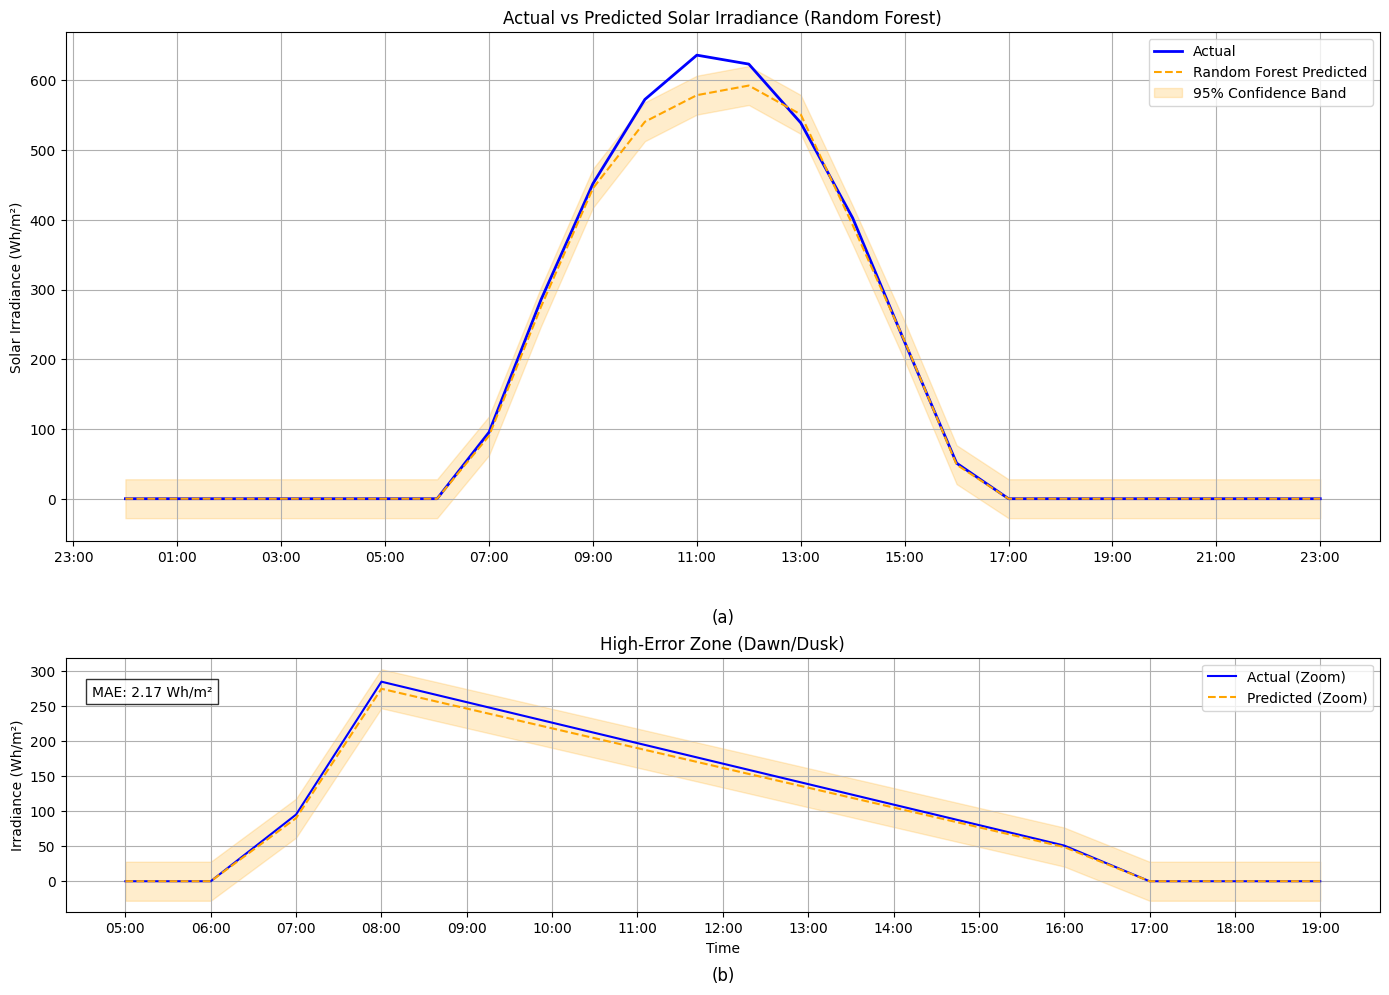

Random Forest R²: 0.9956


In [32]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from sklearn.metrics import r2_score

# Sample data (replace with your actual predictions)
y_pred_rf = rf.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_actual = df_test["All Sky Surface Shortwave Downward Irradiance"]

# --- 1. CONFIDENCE INTERVALS ---
# Calculate prediction residuals and standard deviation
residuals = y_actual - y_pred_rf
std_dev = np.std(residuals)
confidence = 1.96 * std_dev  # 95% CI

# --- 2. PLOT MAIN FIGURE ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [2, 1]})

# Full-period plot
ax1.plot(dates, y_actual, label="Actual", color='blue', linewidth=2)
ax1.plot(dates, y_pred_rf, label="Random Forest Predicted", color='orange', linestyle='--')
ax1.fill_between(dates, 
                 y_pred_rf - confidence, 
                 y_pred_rf + confidence, 
                 color='orange', alpha=0.2, label="95% Confidence Band")

# Dynamic locator selection
if len(dates) > 24:  # Monthly data
    ax1.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
else:  # Daily data
    ax1.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

ax1.set_ylabel("Solar Irradiance (Wh/m²)")
ax1.text(0.5, -0.15, '(a)', transform=ax1.transAxes, 
        ha='center', va='center', fontsize=12)
ax1.set_title("Actual vs Predicted Solar Irradiance (Random Forest)")
ax1.legend()
ax1.grid(True)

# --- 3. ZOOMED-IN HIGH-ERROR SEGMENT (e.g., dawn/dusk) ---
# Identify high-error periods (e.g., 5-8 AM and 4-7 PM)
dates_np = np.array(dates)

# Identify high-error periods (e.g., 5-8 AM and 4-7 PM)
dawn_mask = (dates_np >= np.datetime64('2024-01-01T05:00')) & (dates_np <= np.datetime64('2024-01-01T08:00'))
dusk_mask = (dates_np >= np.datetime64('2024-01-01T16:00')) & (dates_np <= np.datetime64('2024-01-01T19:00'))
high_error_mask = dawn_mask | dusk_mask

# Plot zoomed segment
ax2.plot(dates_np[high_error_mask], y_actual[high_error_mask], label="Actual (Zoom)", color='blue')
ax2.plot(dates_np[high_error_mask], y_pred_rf[high_error_mask], label="Predicted (Zoom)", color='orange', linestyle='--')
ax2.fill_between(dates_np[high_error_mask], 
                 y_pred_rf[high_error_mask] - confidence, 
                 y_pred_rf[high_error_mask] + confidence, 
                 color='orange', alpha=0.2)
# Annotate MAE/RMSE for the zoomed segment
zoom_mae = np.mean(np.abs(y_actual[high_error_mask] - y_pred_rf[high_error_mask]))
ax2.text(0.02, 0.85, f"MAE: {zoom_mae:.2f} Wh/m²", transform=ax2.transAxes, bbox=dict(facecolor='white', alpha=0.8))

# Formatting
ax2.xaxis.set_major_locator(mdates.HourLocator(interval=1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax2.set_xlabel("Time")
ax2.set_ylabel("Irradiance (Wh/m²)")
ax2.set_title("High-Error Zone (Dawn/Dusk)")
ax2.legend()
ax2.grid(True)
ax2.text(0.5, -0.25, '(b)', transform=ax2.transAxes, 
        ha='center', va='center', fontsize=12)

plt.tight_layout()
plt.show()

# --- Print R² scores ---
print(f"Random Forest R²: {r2_score(y_actual, y_pred_rf):.4f}")

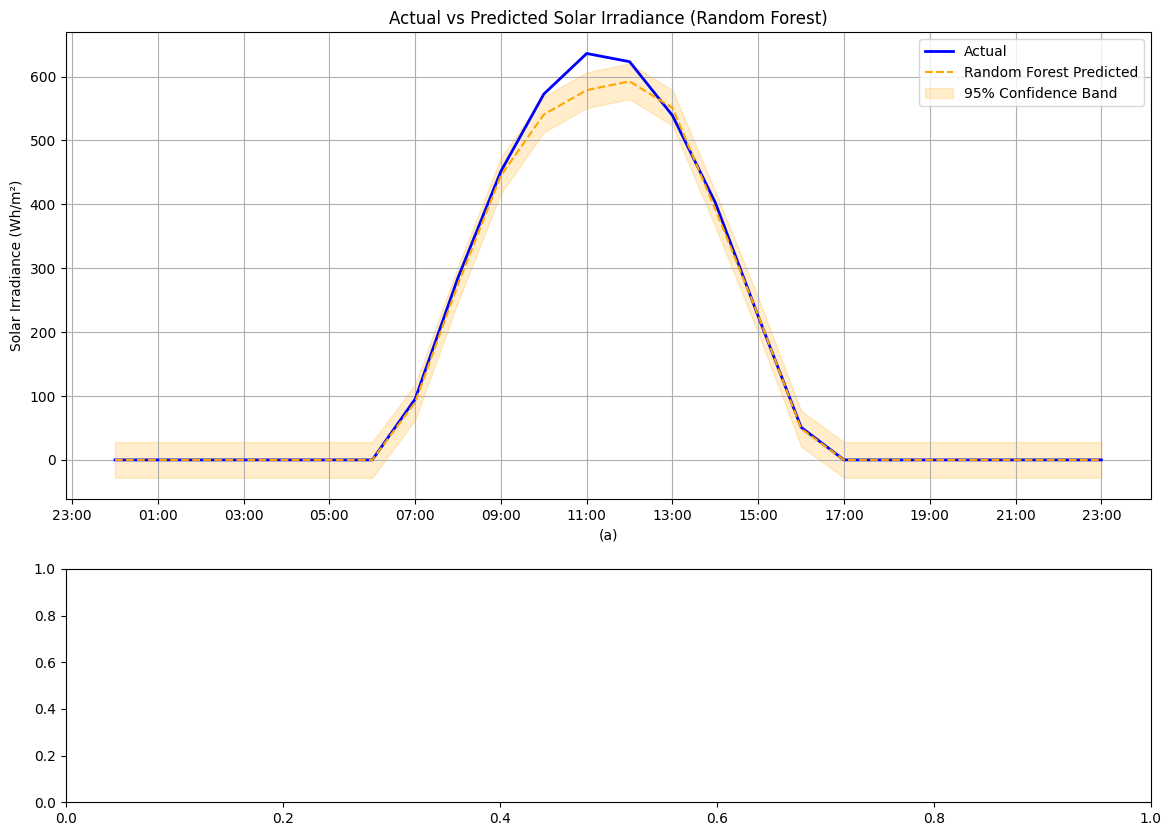

In [29]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [2, 1]})

# Full-period plot
ax1.plot(dates, y_actual, label="Actual", color='blue', linewidth=2)
ax1.plot(dates, y_pred_rf, label="Random Forest Predicted", color='orange', linestyle='--')
ax1.fill_between(dates, 
                 y_pred_rf - confidence, 
                 y_pred_rf + confidence, 
                 color='orange', alpha=0.2, label="95% Confidence Band")

# Dynamic locator selection
if len(dates) > 24:  # Monthly data
    ax1.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
else:  # Daily data
    ax1.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

ax1.set_ylabel("Solar Irradiance (Wh/m²)")
ax1.set_xlabel("(a)")
ax1.set_title("Actual vs Predicted Solar Irradiance (Random Forest)")
ax1.legend()
ax1.grid(True)

In [7]:
#list_prediction = []
#for i in range(len(df_test)):
#    prediction = rf.predict([df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance").iloc[i]])
#    list_prediction.append(prediction[0])

y_pred_lr = lr.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_gb = gb.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_dt = dt.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_rf = rf.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_cnn = model.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_lstm = model_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn_lstm = model_cnn_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn = np.squeeze(y_pred_cnn)
y_pred_lstm = np.squeeze(y_pred_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)

pred = [y_pred_lr, y_pred_gb, y_pred_dt, y_pred_rf, y_pred_cnn, y_pred_lstm, y_pred_cnn_lstm]
for i in range(len(pred)):
    r2 = r2_score(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    mse = mean_squared_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    print(f"R2 {i}: {r2}")
    print(f"MSE {i}: {mse}")
    print(f"RMSE {i}: {rmse}")
    print(f"MAE {i}: {mae}")


#df_test['Predicted All Sky Surface Shortwave Downward Irradiance'] = list_prediction
#df_test['Actuall All Sky Surface Shortwave Downward Irradiance'] = df_test['All Sky Surface Shortwave Downward Irradiance']
#df_test = df_test.drop(columns='All Sky Surface Shortwave Downward Irradiance')
#df_test.to_csv('DecisionTree_Predicted_POWER.csv', index=False)

NameError: name 'lr' is not defined

In [39]:
rf_pred.shape

(14036,)

In [47]:
from scipy.stats import ttest_rel

rf_error = y_test - rf_pred
gb_error = y_test - gb_pred
lr_error = y_test - lr_pred
dt_error = y_test - dt_pred
cnn_pred = np.squeeze(cnn_pred)
cnn_error = y_test - cnn_pred
lstm_error = y_test - lstm_pred
cnn_lstm_error = y_test - cnn_lstm_pred

t_stat, p_value = ttest_rel(rf_error, lr_error)
print(f"RF vs LR p-value = {p_value:.4f}, t-stat = {t_stat:.4f}")

t_stat, p_value = ttest_rel(rf_error, gb_error)
print(f"RF vs GB p-value = {p_value:.4f}, t-stat = {t_stat:.4f}")

t_stat, p_value = ttest_rel(rf_error, dt_error)
print(f"RF vs DT p-value = {p_value:.4f}, t-stat = {t_stat:.4f}")

t_stat, p_value = ttest_rel(rf_error, cnn_error)
print(f"RF vs CNN p-value = {p_value:.4f}, t-stat = {t_stat:.4f}")

t_stat, p_value = ttest_rel(rf_error, lstm_error)
print(f"RF vs LSTM p-value = {p_value:.4f}, t-stat = {t_stat:.4f}")

t_stat, p_value = ttest_rel(rf_error, cnn_lstm_error)
print(f"RF vs CNN-LSTM p-value = {p_value:.4f}, t-stat = {t_stat:.4f}")

RF vs LR p-value = 0.9693, t-stat = 0.0385
RF vs GB p-value = 0.9966, t-stat = -0.0042
RF vs DT p-value = 0.5713, t-stat = 0.5662
RF vs CNN p-value = 0.0001, t-stat = 3.9500
RF vs LSTM p-value = 0.0000, t-stat = -9.5723
RF vs CNN-LSTM p-value = 0.0000, t-stat = -12.1916
